# AI for Actuaries : Hackathon 2026

## Week 1: Build your Pricing Approach

**Objective**

Predict the expected ultimate net claim cost (risk premium) for each policy-period in 2025, net of policy excess and recoveries, excluding repudiated claims.

The modelling approach is based on:

$ \text{Expected Claim Cost} = \text{Exposure} \times \text{Frequency} \times \text{Severity} $



In [ ]:
# Install packages
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
import seaborn as sns

# EDA
from data_profiling import ProfileReport

# Models

warnings.filterwarnings('ignore')

import random
import os

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
os.environ["PYTHONHASHSEED"] = str(SEED)

## Step-by-Step Analysis

### 1. Data Understanding
Load dataset

Show first few rows

Key observations

In [2]:
#Read the datasets
from pathlib import Path

data_dir = Path("data")
if not data_dir.is_dir():
    raise FileNotFoundError(f"Data directory not found: {data_dir.resolve()}")

parquet_files = sorted(data_dir.glob("*.parquet"))
if not parquet_files:
    raise FileNotFoundError(f"No Parquet datasets found in {data_dir.resolve()}")

datasets = {path.stem: pd.read_parquet(path) for path in parquet_files}

display(pd.DataFrame(
    [
        {"dataset": name, "rows": len(df), "columns": len(df.columns), "duplicate rows": df.duplicated().sum()}
        for name, df in datasets.items()
    ]
))

for name, df in datasets.items():
    print(f"\nFirst 10 rows of {name}:")
    print(df.head(10).to_string(index=False))

,dataset,rows,columns,duplicate rows
0,addresses,575983,16,0
1,claims,163150,12,0
2,customers,545240,18,0
3,policies_buildings,707726,27,0
4,policies_contents,721617,28,0
5,policies_motor,979968,39,0
6,sample_submission,626639,2,0
7,test_buildings,184155,26,0
8,test_contents,187498,27,0
9,test_motor,254986,38,0



First 10 rows of addresses:
address_id region urban_density  flood_zone  distance_to_river_km  elevation_m soil_type  year_built property_type roof_type  basement  trees_within_5m  listed_building  bedrooms energy_rating  solar_panels
  A1980663    R05      suburban         1.0                  4.10          9.2      clay        2014      terraced   pitched     False            False            False         3             A         False
  A7251041    R12         urban         1.0                  0.39          4.0     chalk        1969      terraced   pitched     False            False            False         4             C         False
  A4921189    R11         rural         2.0                  0.41         60.0      clay        1952      terraced   pitched     False            False            False         3             C         False
  A9620763    R04         urban         1.0                  6.89          4.7      clay        1881          flat   pitched     False         

### 2. Data Preparation

Objective: Ensure that each row represents a valid policy-period and that reference tables have unique keys. \
Below the table we can see that the average exposure in the policies is more than 1 year.

In [3]:
customers = datasets["customers"].copy()
addresses = datasets["addresses"].copy()
weather = datasets["weather"].copy()
claims = datasets["claims"].copy()

train = {
    line: datasets[f"policies_{line}"].copy()
    for line in ["motor", "buildings", "contents"]
}

test = {
    line: datasets[f"test_{line}"].copy()
    for line in ["motor", "buildings", "contents"]
}

# 1. Check unique keys
print("=== REFERENCE TABLE CHECKS ===")

for name, df, keys in [
    ("customers", customers, ["customer_id"]),
    ("addresses", addresses, ["address_id"]),
    ("weather", weather, ["address_id", "year"]),
    ("claims", claims, ["claim_id"])
]:
    duplicates = df.duplicated(subset=keys).sum()
    status = "PASS" if duplicates == 0 else "FAIL"
    print(f"{name:20} | {status} | Duplicate keys: {duplicates}")

# 2. Check policy-period structure
print("\n=== POLICY-PERIOD CHECKS ===")

results = []

for line in ["motor", "buildings", "contents"]:
    for dataset_type, df in [
        ("train", train[line]),
        ("test", test[line])
    ]:
        df["period_start"] = pd.to_datetime(df["period_start"])
        df["period_end"] = pd.to_datetime(df["period_end"])

        results.append({
            "dataset": f"{dataset_type}_{line}",
            "rows": len(df),
            "duplicate_row_ids": df["row_id"].duplicated().sum(),
            "invalid_dates": (
                df["period_start"] > df["period_end"]
            ).sum(),
            "missing_exposure": df["exposure"].isna().sum(),
            "nonpositive_exposure": (df["exposure"] <= 0).sum(),
            "total_exposure": df["exposure"].sum(),
            "average_exposure": df["exposure"].mean()
        })

quality_report = pd.DataFrame(results)

display(quality_report)

=== REFERENCE TABLE CHECKS ===
customers            | PASS | Duplicate keys: 0
addresses            | PASS | Duplicate keys: 0
weather              | PASS | Duplicate keys: 0
claims               | PASS | Duplicate keys: 0

=== POLICY-PERIOD CHECKS ===


,dataset,rows,duplicate_row_ids,invalid_dates,missing_exposure,nonpositive_exposure,total_exposure,average_exposure
0,train_motor,979968,0,0,0,0,1.058510e+06,1.080147
1,test_motor,254986,0,0,0,0,1.999836e+05,0.784292
2,train_buildings,707726,0,0,0,0,7.894039e+05,1.115409
3,test_buildings,184155,0,0,0,0,1.502439e+05,0.815856
4,train_contents,721617,0,0,0,0,8.107226e+05,1.123480
5,test_contents,187498,0,0,0,0,1.501238e+05,0.800669


From performing these checks we notice that the exposure has a value that is larger than 1. This is not possible as the description of the dataset indicated that each line in the policy datasets in one calender year for each policy.
Checking the exposures indicates that there are some inconsistencies in the data. 

In [4]:
# Check the exposures:
for line in ["motor", "buildings", "contents"]:

    df = datasets[f"policies_{line}"]

    print(f"\n=== {line.upper()} ===")

    print(df["exposure"].describe(
        percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
    ))

    print("Rows with exposure > 1:",
          (df["exposure"] > 1).sum())

    print("Maximum exposure:", df["exposure"].max())

for line in ["motor", "buildings", "contents"]:

    df = datasets[f"policies_{line}"]

    exposure_above_1 = df[df["exposure"] > 1]

    print(f"\n=== {line.upper()} ===")
    print(f"Number of rows with exposure > 1: {len(exposure_above_1)}")

    #display(exposure_above_1)


=== MOTOR ===
count    979968.000000
mean          1.080147
std           9.635858
min           0.002700
1%            0.021900
25%           0.638400
50%           1.000000
75%           1.000000
95%           1.000000
99%           1.000000
max         365.000000
Name: exposure, dtype: float64
Rows with exposure > 1: 3991
Maximum exposure: 365.0

=== BUILDINGS ===
count    707726.000000
mean          1.115409
std           9.779618
min           0.002700
1%            0.027400
25%           0.764400
50%           1.000000
75%           1.000000
95%           1.000000
99%           1.000000
max         365.000000
Name: exposure, dtype: float64
Rows with exposure > 1: 3044
Maximum exposure: 365.0

=== CONTENTS ===
count    721617.00000
mean          1.12348
std          10.16077
min           0.00270
1%            0.02470
25%           0.69860
50%           1.00000
75%           1.00000
95%           1.00000
99%           1.00000
max         365.00000
Name: exposure, dtype: float64
R

In [5]:
# Recalculate exposure quality report

results = []

for line in ["motor", "buildings", "contents"]:
    for dataset_type, df in [
        ("train", train[line]),
        ("test", test[line])
    ]:

        df["period_start"] = pd.to_datetime(df["period_start"])
        df["period_end"] = pd.to_datetime(df["period_end"])

        # Recalculate exposure based on actual days covered
        days_covered = (
            df["period_end"] - df["period_start"]
        ).dt.days + 1

        # Account for leap years
        days_in_year = np.where(
            df["period_start"].dt.is_leap_year,
            366,
            365
        )

        df["exposure_corrected"] = days_covered / days_in_year

        # Build quality report using corrected exposure
        results.append({
            "dataset": f"{dataset_type}_{line}",
            "rows": len(df),
            "duplicate_row_ids": df["row_id"].duplicated().sum(),
            "invalid_dates": (
                df["period_start"] > df["period_end"]
            ).sum(),
            "missing_exposure": df["exposure_corrected"].isna().sum(),
            "nonpositive_exposure": (
                df["exposure_corrected"] <= 0
            ).sum(),
            "total_exposure": df["exposure_corrected"].sum(),
            "average_exposure": df["exposure_corrected"].mean(),
            "max_exposure": df["exposure_corrected"].max(),
            "original_average_exposure": df["exposure"].mean()
        })

quality_report = pd.DataFrame(results)

display(quality_report.round(4))

,dataset,rows,duplicate_row_ids,invalid_dates,missing_exposure,nonpositive_exposure,total_exposure,average_exposure,max_exposure,original_average_exposure
0,train_motor,979968,0,0,0,0,786611.6609,0.8027,1.0,1.0801
1,test_motor,254986,0,0,0,0,199983.5808,0.7843,1.0,0.7843
2,train_buildings,707726,0,0,0,0,590150.5701,0.8339,1.0,1.1154
3,test_buildings,184155,0,0,0,0,150243.9041,0.8159,1.0,0.8159
4,train_contents,721617,0,0,0,0,590449.5397,0.8182,1.0,1.1235
5,test_contents,187498,0,0,0,0,150123.7699,0.8007,1.0,0.8007


In [6]:
# After performing the exposure correction, we will update the original exposure column with the corrected values in both train and test datasets.
for line in train:
    train[line]["exposure"] = train[line]["exposure_corrected"]

for line in test:
    test[line]["exposure"] = test[line]["exposure_corrected"]


Merge customer and adress info.
Objective: Enrich policy-level features before building the target.
These are many-to-one joins: each policy-period belongs to one customer and references one insured address.

In [7]:
def enrich_static_features(df, line, dataset_name):
    initial_rows = len(df)

    enriched = df.merge(
        customers,
        on="customer_id",
        how="left",
        validate="many_to_one"
    )

    enriched = enriched.merge(
        addresses,
        on="address_id",
        how="left",
        validate="many_to_one"
    )

    enriched_rows = len(enriched)
    if enriched_rows != initial_rows:
        print(
            f"{dataset_name} {line}: FAIL — row count changed from "
            f"{initial_rows} to {enriched_rows}"
        )
        raise ValueError(
            f"Row count changed during customer/address enrichment "
            f"for {dataset_name} {line}"
        )

    print(f"{dataset_name} {line}: PASS — row count unchanged ({initial_rows})")

    return enriched


print("Check AI code:")

train = {
    line: enrich_static_features(df, line, "Train")
    for line, df in train.items()
}

test = {
    line: enrich_static_features(df, line, "Test")
    for line, df in test.items()
}

Check AI code:
Train motor: PASS — row count unchanged (979968)
Train buildings: PASS — row count unchanged (707726)
Train contents: PASS — row count unchanged (721617)
Test motor: PASS — row count unchanged (254986)
Test buildings: PASS — row count unchanged (184155)
Test contents: PASS — row count unchanged (187498)


#### Step 4 — Engineer historical weather features
Objective: Add weather risk information without using future observations.
We should not use actual weather from 2025 to predict 2025 risk premium. Equally, for a 2023 policy we should not use actual weather outcomes from 2023 when simulating a prediction made at inception.
A starting approach is to use previous-year weather.

In [8]:
# Identify weather variables
weather_columns = [
    col for col in weather.columns
    if col not in ["address_id", "year"]
]

# Rename weather columns to indicate lagged features
weather_lagged = weather.rename(
    columns={
        "year": "previous_year",
        **{
            col: f"lag1_{col}"
            for col in weather_columns
        }
    }
)

# Check uniqueness of weather records
assert not weather_lagged.duplicated(
    subset=["address_id", "previous_year"]
).any(), "Duplicate address-year combinations in weather data"


# Function to merge historical weather
def merge_weather(df, line, dataset_name):

    result = df.copy()

    # Derive year from the policy-period start date
    result["period_start"] = pd.to_datetime(
        result["period_start"]
    )

    result["year"] = result["period_start"].dt.year

    # Use 2021 weather for 2021 policies,
    # previous-year weather for all subsequent years
    result["previous_year"] = np.where(
        result["year"] == 2021,
        2021,
        result["year"] - 1
    )

    original_rows = len(result)

    # Merge weather
    result = result.merge(
        weather_lagged,
        on=["address_id", "previous_year"],
        how="left",
        validate="many_to_one"
    )

    # Check row count
    merged_rows = len(result)

    if merged_rows != original_rows:
        print(
            f"{dataset_name} {line}: FAIL — row count changed from "
            f"{original_rows} to {merged_rows}"
        )
        raise ValueError(
            f"Row count changed during weather enrichment "
            f"for {dataset_name} {line}"
        )

    print(
        f"{dataset_name} {line}: PASS — "
        f"row count unchanged ({original_rows:,})"
    )

    return result.drop(columns="previous_year")


# For now also add weather data to motor
print("Check weather enrichment:")

# Apply to training datasets
train = {
    line: merge_weather(df, line, "Train")
    for line, df in train.items()
}

# Apply to test datasets
test = {
    line: merge_weather(df, line, "Test")
    for line, df in test.items()
}

Check weather enrichment:
Train motor: PASS — row count unchanged (979,968)
Train buildings: PASS — row count unchanged (707,726)
Train contents: PASS — row count unchanged (721,617)
Test motor: PASS — row count unchanged (254,986)
Test buildings: PASS — row count unchanged (184,155)
Test contents: PASS — row count unchanged (187,498)


#### Step 5 — Match claims to the correct policy-period
Objective: Assign every historical claim to the exact row covering its loss date.
This is the most important merge in the workflow.
We cannot join claims only on policy_id, because a policy may have multiple rows across different years or mid-term changes. So we do not first perform aggregation on the claims table with policy_id and loss year because there might be multiple policy versions within a year.


First, combine the policy-period identifiers into a temporary lookup table. This includes the policy_id and the start and end date of that version of the policy.

At the end there are some claims that are unmatched. As an actuary, it is necesarry to perform a check on the data to understand why this occurs. A diagnostic indicates that the loss date occured before the start date of the policy. In the majority of the cases, the reporting date did occur when a policy was risk-bearing. Therefore, the decision is made to link the "unmatched" cases to the policy such that loss date is nearest to the policy instance.

In [9]:
policy_windows = pd.concat(
    [
        datasets[f"policies_{line}"][
            ["row_id", "policy_id", "period_start", "period_end"]
        ].assign(line=line)
        for line in ["motor", "buildings", "contents"]
    ],
    ignore_index=True
)

policy_windows["period_start"] = pd.to_datetime(
    policy_windows["period_start"]
)
policy_windows["period_end"] = pd.to_datetime(
    policy_windows["period_end"]
)


## Exclude repudiated claims, then match the remaining claims to policy periods.
claims_for_matching = claims.loc[
    claims["status"] != "repudiated"
].copy()
claims_for_matching["loss_date"] = pd.to_datetime(
    claims_for_matching["loss_date"]
)

claims_with_policy_windows = claims_for_matching.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="left"
)

claims_matched = claims_with_policy_windows.loc[
    (claims_with_policy_windows["loss_date"] >= claims_with_policy_windows["period_start"])
    &
    (claims_with_policy_windows["loss_date"] <= claims_with_policy_windows["period_end"])
].copy()

print("Claims excluded (repudiated):", len(claims) - len(claims_for_matching))
print("Claims included in matching:", len(claims_for_matching))
print("Matched claims:", len(claims_matched))

print(
    "Claims with multiple matches:",
    claims_matched["claim_id"].duplicated().sum()
)

assert claims_matched["claim_id"].is_unique

unmatched_claims = claims_for_matching.loc[
    ~claims_for_matching["claim_id"].isin(claims_matched["claim_id"])
].copy()

unmatched_policy_windows = unmatched_claims.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="left",
    indicator=True
)

policy_window_summary = (
    unmatched_policy_windows.groupby("claim_id")
    .agg(
        policy_found=("_merge", lambda matches: matches.eq("both").any()),
        first_period_start=("period_start", "min"),
        last_period_end=("period_end", "max")
    )
    .reset_index()
)

unmatched_claim_diagnostics = unmatched_claims[
    ["claim_id", "policy_id", "line", "loss_date",  "report_date"]
].merge(policy_window_summary, on="claim_id", how="left")

reasons = [
    unmatched_claim_diagnostics["loss_date"].isna(),
    ~unmatched_claim_diagnostics["policy_found"],
    unmatched_claim_diagnostics["first_period_start"].isna()
    | unmatched_claim_diagnostics["last_period_end"].isna(),
    unmatched_claim_diagnostics["loss_date"]
    < unmatched_claim_diagnostics["first_period_start"],
    unmatched_claim_diagnostics["loss_date"]
    > unmatched_claim_diagnostics["last_period_end"]
]
reason_labels = [
    "Missing loss date",
    "No matching policy_id and line",
    "Missing policy period dates",
    "Loss before first policy period",
    "Loss after last policy period"
]
unmatched_claim_diagnostics["reason"] = np.select(
    reasons,
    reason_labels,
    default="Gap between policy periods"
)

print("Check AI code:")
print("Unmatched claims:", len(unmatched_claim_diagnostics))
print("Unmatched claim reasons:")
print(unmatched_claim_diagnostics["reason"].value_counts().to_string())



# Find candidate periods for claims that did not match by loss date
nearest_candidates = unmatched_claims.merge(
    policy_windows,
    on=["policy_id", "line"],
    how="inner",
    validate="many_to_many"
)

# Distance is zero if the date is inside the interval; otherwise, use
# the number of days to the nearest period boundary.
nearest_candidates["distance_days"] = np.select(
    [
        nearest_candidates["loss_date"] < nearest_candidates["period_start"],
        nearest_candidates["loss_date"] > nearest_candidates["period_end"],
    ],
    [
        (nearest_candidates["period_start"] - nearest_candidates["loss_date"]).dt.days,
        (nearest_candidates["loss_date"] - nearest_candidates["period_end"]).dt.days,
    ],
    default=0
)

# Select one nearest policy-period for each claim.
nearest_matches = (
    nearest_candidates
    .dropna(subset=["loss_date", "period_start", "period_end"])
    .sort_values(["claim_id", "distance_days", "period_start", "row_id"])
    .drop_duplicates("claim_id", keep="first")
    .copy()
)

nearest_matches["match_method"] = "nearest_period"
claims_matched["match_method"] = "loss_date_within_period"

# Add nearest-period assignments to the existing exact matches.
claims_matched = pd.concat(
    [claims_matched, nearest_matches],
    ignore_index=True
)

assert claims_matched["claim_id"].is_unique

print("Claims assigned to nearest period:", len(nearest_matches))
print("Claims still without a policy period:",
      len(unmatched_claims) - len(nearest_matches))

Claims excluded (repudiated): 1711
Claims included in matching: 161439
Matched claims: 161029
Claims with multiple matches: 0
Check AI code:
Unmatched claims: 410
Unmatched claim reasons:
reason
Loss before first policy period    410
Claims assigned to nearest period: 410
Claims still without a policy period: 0


#### Step 6 — Calculate the observed net incurred claim cost
Objective: Construct a historical cost measure consistent with the target.
According to the data dictionary:
- paid_to_date is already net of excess.
- incurred_to_date consists of paid amounts and the open-claim case estimate.
- recoveries is a separate amount, but it is not confirmed whether incurred already reflects it.
- Repudiated claims must be excluded.

Our provisional assumption is:
$ \text{Observed Net Incurred} = \text{Incurred to Date} - \text{Recoveries} $

We must not deduct the policy excess again.

In [10]:
claims_matched["recoveries"] = (
    claims_matched["recoveries"].fillna(0)
)

# Working assumption: recoveries are NOT yet deducted from incurred_to_date.
RECOVERIES_ALREADY_NETTED = False

if RECOVERIES_ALREADY_NETTED:
    claims_matched["net_cost_before_status"] = (
        claims_matched["incurred_to_date"]
    )
else:
    claims_matched["net_cost_before_status"] = (
        claims_matched["incurred_to_date"]
        - claims_matched["recoveries"]
    )

claims_matched["net_incurred"] = np.where(
    claims_matched["net_cost_before_status"] > 0,
    claims_matched["net_cost_before_status"],
    0
)

# Final reconciliation:
display(
    claims_matched.groupby(["line", "status"]).agg(
        claims=("claim_id", "count"),
        incurred=("incurred_to_date", "sum"),
        recoveries=("recoveries", "sum"),
        net_incurred=("net_incurred", "sum")
    )
)

negative_claims = claims_matched[
    claims_matched["net_incurred"] < 0
]

print("Negative net incurred claims:", len(negative_claims))

claims      incurred   recoveries  net_incurred
line      status                                                 
buildings closed   24549  2.169569e+08         0.00  2.169569e+08
          open      1893  3.124254e+07         0.00  3.124254e+07
contents  closed   22992  6.265879e+07         0.00  6.265879e+07
          open       810  3.470007e+06         0.00  3.470007e+06
motor     closed  103751  3.773012e+08  27678633.34  3.496226e+08
          open      7444  8.210164e+07         0.00  8.210164e+07

Negative net incurred claims: 0


#### Step 7 — Aggregate claims at policy-period level, and per policy level generate the target values:
- $N_{i}$ : number of claims per policy, given that exposure =1.
- the average claims cost, given that N > 0.

Objective: Construct the two historical responses: N and total observed claim cost.


In [11]:
# 1. Define targets
targets = (
    claims_matched
    .groupby("row_id", as_index=False)
    .agg(
        nclaims=("claim_id", "nunique"),
        net_incurred=("net_incurred", "sum")
    )
)

targets["nclaims"] = targets["nclaims"].astype(int)


# 2. Merge targets into each line of business
for line, df in train.items():

    initial_rows = len(df)

    # Remove target columns if cell is rerun
    df = df.drop(
        columns=["nclaims", "net_incurred", "avg_sev"],
        errors="ignore"
    )

    # Merge targets
    df = df.merge(
        targets,
        on="row_id",
        how="left",
        validate="one_to_one"
    )

    # Fill missing values
    df["nclaims"] = df["nclaims"].fillna(0).astype(int)
    df["net_incurred"] = df["net_incurred"].fillna(0)

    # Average severity: 0 when nclaims = 0
    df["avg_sev"] = (
        df["net_incurred"]
        / df["nclaims"].replace(0, np.nan)
    ).fillna(0)


    # Validate
    assert len(df) == initial_rows, (
        f"{line}: Row count changed from "
        f"{initial_rows} to {len(df)}"
    )

    train[line] = df

    print(
        f"{line}: {len(df):,} rows preserved | "
        f"{df['nclaims'].sum():,} claims | "
        f"{df['net_incurred'].sum():,.2f} net incurred"
    )

motor: 979,968 rows preserved | 111,195 claims | 431,724,224.25 net incurred
buildings: 707,726 rows preserved | 26,442 claims | 248,199,474.78 net incurred
contents: 721,617 rows preserved | 23,802 claims | 66,128,796.73 net incurred


#### Step 8 — Assess claim development to ultimate
Objective: Correct the mismatch between observed incurred and ultimate costs.
At 31 December 2024:
- Some 2024 losses are not yet reported (IBNR).
- Some reported claims remain open and may develop.
- Future recoveries may not yet be reflected.
Therefore, modelling observed_net_incurred directly will generally underestimate ultimate loss costs if those effects are material.
Ideally, use historical valuation snapshots to build paid/incurred development triangles. However, the supplied claims table has only one snapshot, so reliable chain-ladder development factors cannot be estimated from this table alone.
If validated development-to-ultimate factors become available, you can apply them at a suitable line/peril/accident-year level.

In [12]:
# No estimated development factors are supplied yet.
# These should NOT be treated as genuine ultimate estimates.

for line in train:
    train[line]["development_factor"] = 1.0

    train[line]["avg_sev"] = (
        train[line]["avg_sev"]
        * train[line]["development_factor"]
    )

Here I want a visualization of how the datasets are cleaned from before , to after and the variables that were added

In [13]:
lines_for_comparison = {
    "Motor": "motor",
    "Buildings": "buildings",
    "Contents": "contents",
}

target_columns = ["nclaims", "avg_sev"]

# Summarize rows, exposure, target availability, and dtype counts.
comparison_rows = []
schema_rows = []

for label, line in lines_for_comparison.items():
    before = datasets[f"policies_{line}"]
    after = train[line]

    comparison_rows.extend([
        {
            "line": label,
            "stage": "Before",
            "rows": len(before),
            "columns": len(before.columns),
            "mean exposure": before["exposure"].mean(),
            "total exposure": before["exposure"].sum(),
            "targets present": "None",
        },
        {
            "line": label,
            "stage": "After",
            "rows": len(after),
            "columns": len(after.columns),
            "mean exposure": after["exposure"].mean(),
            "total exposure": after["exposure"].sum(),
            "targets present": ", ".join(
                col for col in target_columns if col in after.columns
            ),
        },
    ])

    before_cols = set(before.columns)
    after_cols = set(after.columns)

    for col in sorted(before_cols | after_cols):
        schema_rows.append({
            "line": label,
            "column": col,
            "before dtype": str(before[col].dtype) if col in before_cols else "—",
            "after dtype": str(after[col].dtype) if col in after_cols else "—",
            "change": (
                "Added" if col not in before_cols else
                "Removed" if col not in after_cols else
                "Retained"
            ),
        })

comparison_summary = pd.DataFrame(comparison_rows)
schema_comparison = pd.DataFrame(schema_rows)

display(comparison_summary.round(3))
#display(schema_comparison)


,line,stage,rows,columns,mean exposure,total exposure,targets present
0,Motor,Before,979968,39,1.080,1058509.681,None
1,Motor,After,979968,84,0.803,786611.661,"nclaims, avg_sev"
2,Buildings,Before,707726,27,1.115,789403.927,None
3,Buildings,After,707726,72,0.834,590150.570,"nclaims, avg_sev"
4,Contents,Before,721617,28,1.123,810722.569,None
5,Contents,After,721617,73,0.818,590449.540,"nclaims, avg_sev"


In [14]:
print(train["motor"].head(10).to_string())

      row_id  policy_id customer_id address_id period_start period_end  exposure  driver_age  years_licensed  ncb_years  vehicle_value_group  vehicle_age make_model  engine_size_cc  body_type transmission  seats vehicle_colour fuel_type  driver_assist     cover_type  annual_mileage overnight_parking vehicle_use  named_young_driver  telematics_opt_in  telematics_score  voluntary_excess  compulsory_excess          channel payment_method  missed_payments_12m  new_business  renewal_count  days_quote_to_inception  discount_applied  written_premium  customer_service_contacts renewal_decision  exposure_corrected     surname date_of_birth   occupation marital_status  household_size credit_band  prior_claims_5y  licence_points  years_at_address  customer_since_year email_domain marketing_consent document_preference previous_insurer campaign_code  branch_id  marketing_segment region urban_density  flood_zone  distance_to_river_km  elevation_m soil_type  year_built property_type roof_type  baseme

### 3. EDA

In [ ]:
# Directory for HTML reports
report_dir = Path("profile_reports")
report_dir.mkdir(parents=True, exist_ok=True)

# Datasets to profile
profile_datasets = {
    "policies_motor": datasets["policies_motor"],
    "policies_buildings": datasets["policies_buildings"],
    "policies_contents": datasets["policies_contents"],
    "addresses": datasets["addresses"],
    "customers": datasets["customers"],
}

# Generate and save reports
for name, df in profile_datasets.items():
    print(f"Generating profile report: {name}")

    profile = ProfileReport(
        df,
        title=f"Profiling Report - {name}",
        explorative=True,
        minimal=True
    )

    output_path = report_dir / f"{name}_profile.html"
    profile.to_file(output_path)

    print(f"Saved: {output_path}")

print("All profile reports generated successfully.")

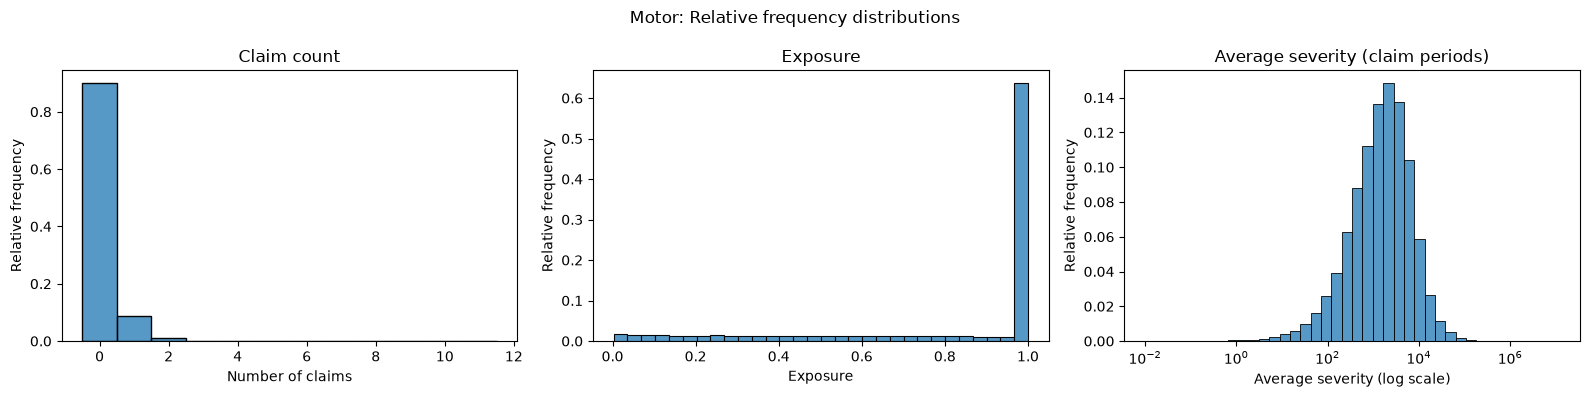

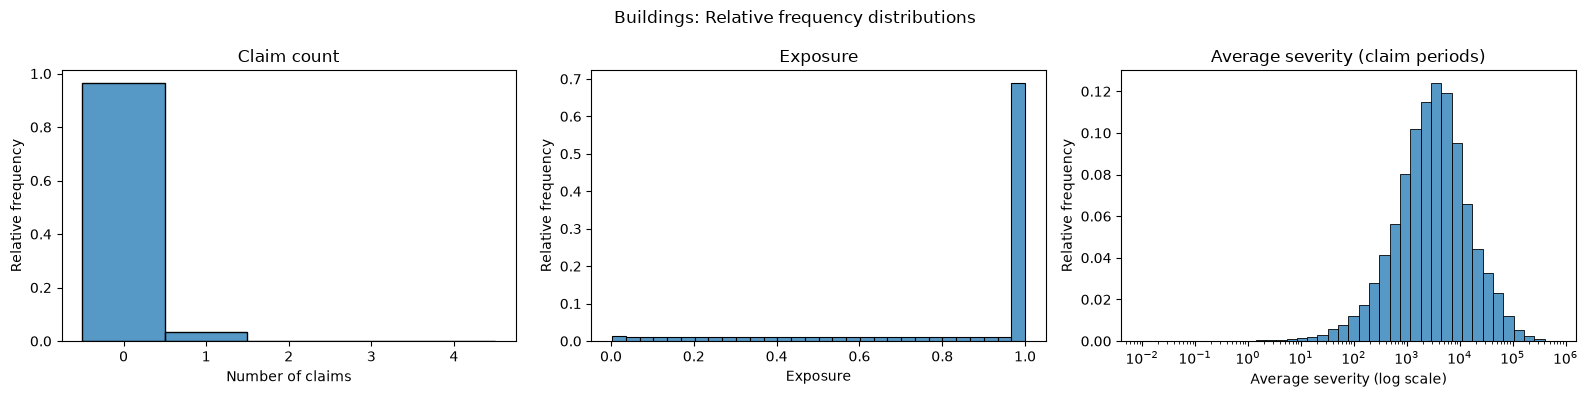

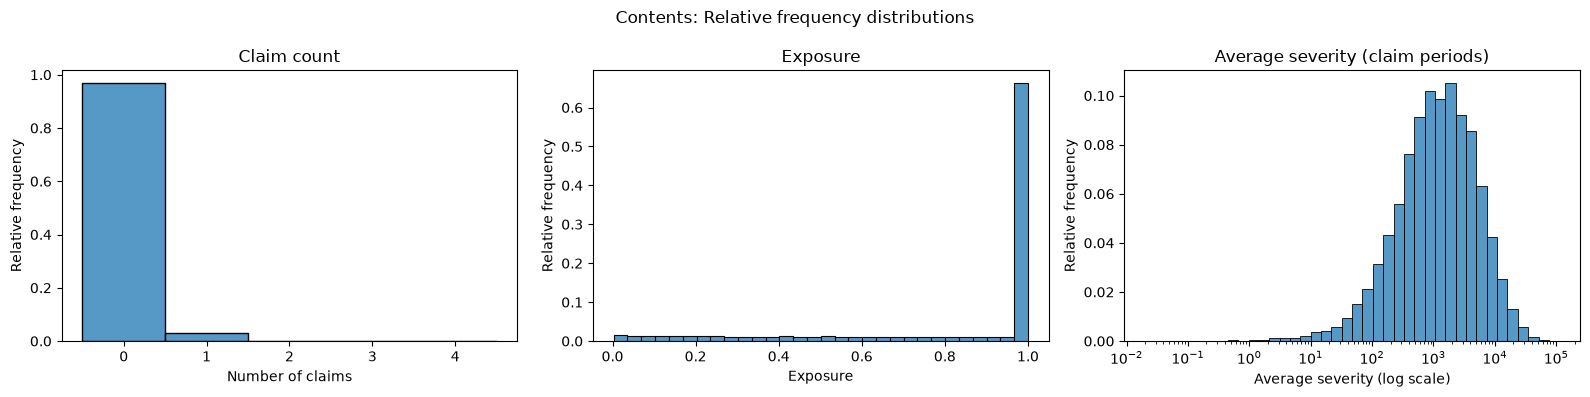

In [15]:
for label, line in lines_for_comparison.items():
    df = train[line]

    fig, axes = plt.subplots(1, 3, figsize=(16, 4))

    sns.histplot(
        data=df,
        x="nclaims",
        discrete=True,
        stat="probability",
        ax=axes[0]
    )
    axes[0].set(
        title="Claim count",
        xlabel="Number of claims",
        ylabel="Relative frequency"
    )

    sns.histplot(
        data=df,
        x="exposure",
        bins=30,
        stat="probability",
        ax=axes[1]
    )
    axes[1].set(
        title="Exposure",
        xlabel="Exposure",
        ylabel="Relative frequency"
    )

    positive_severity = df.loc[df["avg_sev"] > 0, "avg_sev"]
    sns.histplot(
        x=positive_severity,
        bins=40,
        stat="probability",
        log_scale=True,
        ax=axes[2]
    )
    axes[2].set(
        title="Average severity (claim periods)",
        xlabel="Average severity (log scale)",
        ylabel="Relative frequency"
    )

    fig.suptitle(f"{label}: Relative frequency distributions")
    plt.tight_layout()
    plt.show()

In [16]:
severity_data = pd.concat(
    [df.assign(line=line) for line, df in train.items()],
    ignore_index=True
)

plot_data = severity_data.loc[
    (severity_data["nclaims"] > 0) & severity_data["avg_sev"].notna()
].copy()

severity_comparison = (
    plot_data.groupby("line")["avg_sev"]
    .agg(
        count="count",
        median="median",
        p75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99),
        max="max",
    )
)

severity_comparison["IQR"] = (
    severity_comparison["p75"]
    - plot_data.groupby("line")["avg_sev"].quantile(0.25)
)
severity_comparison["upper_fence"] = (
    severity_comparison["p75"] + 1.5 * severity_comparison["IQR"]
)

outlier_counts = (
    plot_data.groupby("line")
    .apply(lambda group: (group["avg_sev"] > severity_comparison.loc[group.name, "upper_fence"]).sum())
)
severity_comparison["outliers_above_fence"] = outlier_counts

display(severity_comparison.round(2))

,count,median,p75,p90,p95,p99,max,IQR,upper_fence,outliers_above_fence
line,,,,,,,,,,
buildings,25426,3160.42,8180.04,21071.28,38933.59,98222.80,631246.21,7050.49,18755.78,2857
contents,22963,1205.93,3211.80,6853.96,10500.49,21758.24,111900.00,2772.85,7371.07,2051
motor,98326,1627.88,4008.53,8230.94,12803.06,34276.06,11894276.93,3445.29,9176.46,8348


This is particularly useful for identifying whether the differences are in attritional claims or large losses.

### 4. Train test split.

In [17]:
# Define training and validation years
TRAIN_YEARS = [2021, 2022, 2023]
VALIDATION_YEAR = 2024

# Keep separate dictionaries for training and validation
train_split = {}
valid_split = {}

for line, df in train.items():

    df = df.copy()
    df["year"] = pd.to_datetime(
        df["period_start"]
    ).dt.year

    train_split[line] = df[
        df["year"].isin(TRAIN_YEARS)
    ].copy()

    valid_split[line] = df[
        df["year"] == VALIDATION_YEAR
    ].copy()

    print(f"\n=== {line.upper()} ===")
    print(f"Training rows:   {len(train_split[line]):,}")
    print(f"Validation rows: {len(valid_split[line]):,}")

    assert set(train_split[line]["row_id"]).isdisjoint(
        set(valid_split[line]["row_id"])
    )


=== MOTOR ===
Training rows:   725,270
Validation rows: 254,698

=== BUILDINGS ===
Training rows:   523,725
Validation rows: 184,001

=== CONTENTS ===
Training rows:   534,126
Validation rows: 187,491


In [18]:
def portfolio_summary(df):
    exposure = df["exposure"].sum()
    claims = df["nclaims"].sum()
    incurred = df["net_incurred"].sum()

    return pd.Series({
        "rows": len(df),
        "exposure": exposure,
        "claims": claims,
        "frequency": claims / exposure,
        "avg_severity": (
            incurred / claims if claims > 0 else np.nan
        ),
        "pure_premium": incurred / exposure
    })


split_summary = pd.concat(
    {
        line: pd.DataFrame({
            "train": portfolio_summary(train_split[line]),
            "validation": portfolio_summary(valid_split[line])
        }).T
        for line in train
    },
    names=["line", "split"]
)

display(split_summary.round(3))

rows    exposure   claims  frequency  avg_severity  \
line      split                                                                
motor     train       725270.0  587371.893  85316.0      0.145      3996.818   
          validation  254698.0  199239.768  25879.0      0.130      3505.998   
buildings train       523725.0  440642.658  19865.0      0.045      9097.815   
          validation  184001.0  149507.913   6577.0      0.044     10258.685   
contents  train       534126.0  440892.521  17810.0      0.040      2728.567   
          validation  187491.0  149557.019   5992.0      0.040      2926.071   

                      pure_premium  
line      split                     
motor     train            580.539  
          validation       455.390  
buildings train            410.147  
          validation       451.290  
contents  train            110.221  
          validation       117.233

For this first draft, use a small set of relatively stable underwriting features rather than every available variable.
This reduces the risk of leakage and lets you establish whether the model works before adding complexity.

### 5. Training the model

This is the piece of the code that can easily be adapted. Add new models here.

In [19]:
import numpy as np
import pandas as pd
from itertools import product

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import PoissonRegressor, GammaRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import (
    mean_poisson_deviance,
    mean_gamma_deviance,
    mean_tweedie_deviance,
    mean_absolute_error
)

SEED = 42

LINES = list(train_split)
EXPOSURE = "exposure"
FREQ_TARGET = "nclaims"
SEV_TARGET = "avg_sev"
COST_TARGET = "net_incurred"
CAP_QUANTILE = 0.995


# Add or remove algorithms here.
MODEL_GRIDS = {
    "frequency": {
        "glm": {
            "alpha": [0.001, 0.01, 0.1, 1.0]
        },
        "tree": {
            "max_depth": [3, 5],
            "min_samples_leaf": [500, 2000]
        },
        "xgboost": {
            "max_depth": [3, 5],
            "learning_rate": [0.05],
            "n_estimators": [300],
            "subsample": [0.8]
        }
    },
    "severity": {
        "glm": {
            "alpha": [0.001, 0.01, 0.1, 1.0]
        },
        "tree": {
            "max_depth": [3, 5],
            "min_samples_leaf": [100, 500]
        },
        "xgboost": {
            "max_depth": [3, 5],
            "learning_rate": [0.05],
            "n_estimators": [300],
            "subsample": [0.8]
        }
    }
}

# For the first run, compare only GLMs and trees.
# Add "xgboost" when ready.
ACTIVE_MODELS = {
    "frequency": ["xgboost"],
    "severity": [ "xgboost"]
}



# Columns that should never be predictors
exclude = {
    "row_id",
    "policy_id",
    "customer_id",
    "address_id",
    "period_start",
    "period_end",
    "year",
    "exposure",
    "exposure_original",
    "exposure_corrected",
    "exposure_difference",
    "nclaims",
    "avg_sev",
    "avg_claim",
    "net_incurred",
    "positive_incurred",
    "nclaims_positive",
    "avg_sev_positive",
    "development_factor", 
    "renewal_decision", #This is not included in the test set
    "surname",
    "prior_claims_5y",
    "years_at_address", "licence_points", "customer_since_year", "written_premium",
    "customer_service_contacts"
}

features = {
    line: [
        col for col in df.columns
        if col not in exclude
        and (
            pd.api.types.is_numeric_dtype(df[col])
            or pd.api.types.is_object_dtype(df[col])
            or isinstance(df[col].dtype, pd.CategoricalDtype)
            or pd.api.types.is_string_dtype(df[col])
        )
    ]
    for line, df in train_split.items()
}

for line, cols in features.items():
    print("Features included in the model:")
    print(f"\n{line}: {len(cols)} features")
    print(cols)

Features included in the model:

motor: 63 features
['driver_age', 'years_licensed', 'ncb_years', 'vehicle_value_group', 'vehicle_age', 'make_model', 'engine_size_cc', 'body_type', 'transmission', 'seats', 'vehicle_colour', 'fuel_type', 'driver_assist', 'cover_type', 'annual_mileage', 'overnight_parking', 'vehicle_use', 'named_young_driver', 'telematics_opt_in', 'telematics_score', 'voluntary_excess', 'compulsory_excess', 'channel', 'payment_method', 'missed_payments_12m', 'new_business', 'renewal_count', 'days_quote_to_inception', 'discount_applied', 'date_of_birth', 'occupation', 'marital_status', 'household_size', 'credit_band', 'email_domain', 'marketing_consent', 'document_preference', 'previous_insurer', 'campaign_code', 'branch_id', 'marketing_segment', 'region', 'urban_density', 'flood_zone', 'distance_to_river_km', 'elevation_m', 'soil_type', 'year_built', 'property_type', 'roof_type', 'basement', 'trees_within_5m', 'listed_building', 'bedrooms', 'energy_rating', 'solar_panels

2. Data preparation and validation checks
Frequency uses all policy-periods. Severity uses only rows with strictly positive average claim cost.
We don't need separate permanent train_freq and train_sev dictionaries: the filtering can happen inside one training function.

In [20]:
def severity_filter(df):
    return df.loc[
        (df[SEV_TARGET] > 0)
    ].copy()


def check_data(df):
    assert (df[EXPOSURE] > 0).all()
    assert df[FREQ_TARGET].notna().all()
    assert (df[FREQ_TARGET] >= 0).all()
    assert np.isfinite(df[COST_TARGET]).all()
    assert (df[COST_TARGET] >= 0).all()


for line in LINES:
    check_data(train_split[line])
    check_data(valid_split[line])

    forbidden = {
        "row_id", "policy_id", "customer_id",
        "nclaims", "avg_sev", "net_incurred", "avg_claim", "development_factor"
    }

    assert not (set(features[line]) & forbidden), (
        f"{line}: target or identifier leakage in features"
    )

3. Shared preprocessing
For easy comparison across models, let's initially use the same one-hot encoded feature matrix.

In [21]:
def build_preprocessor(df, cols):

    numeric = [
        c for c in cols
        if pd.api.types.is_numeric_dtype(df[c])
    ]
    categorical = [
        c for c in cols
        if c not in numeric
    ]

    return ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scale", StandardScaler())
        ]), numeric),

        ("cat", Pipeline([
            ("imputer", SimpleImputer(
                strategy="most_frequent"
            )),
            ("onehot", OneHotEncoder(
                handle_unknown="ignore",
                min_frequency=100
            ))
        ]), categorical)
    ])

4. Model factory
This is the key to making your pipeline flexible.
All model algorithms are defined in one function.


In [22]:
def make_model(task, algorithm, params):

    if task == "frequency":

        if algorithm == "glm":
            return PoissonRegressor(
                **params,
                max_iter=500
            )

        if algorithm == "tree":
            return DecisionTreeRegressor(
                criterion="poisson",
                random_state=SEED,
                **params
            )

        if algorithm == "xgboost":
            from xgboost import XGBRegressor

            return XGBRegressor(
                objective="count:poisson",
                tree_method="hist",
                random_state=SEED,
                n_jobs=-1,
                **params
            )

    elif task == "severity":

        if algorithm == "glm":
            return GammaRegressor(
                **params,
                max_iter=500
            )

        if algorithm == "tree":
            return DecisionTreeRegressor(
                criterion="poisson",
                random_state=SEED,
                **params
            )

        if algorithm == "xgboost":
            from xgboost import XGBRegressor

            return XGBRegressor(
                objective="reg:gamma",
                tree_method="hist",
                random_state=SEED,
                n_jobs=-1,
                **params
            )

    raise ValueError(f"Unknown combination: {task}, {algorithm}")



The main complication is exposure: scikit-learn's Poisson GLM and trees do not accept a dedicated offset, whereas XGBoost can incorporate a log-exposure base margin.
The following adapter hides that difference from the rest of the pipeline.

The first few lines of fit_component above can be simplified: we'll always pass severity-filtered inputs when fitting severity, so the only required check is that len(df) > 0.
This adapter means you can swap between Poisson GLM, a tree and XGBoost without changing how the final claim count is computed. Note that regularization and tree-splitting conventions can differ across implementations, so exposure equivalence refers to the underlying Poisson loss, not necessarily identical fitted models.

In [23]:
def fit_component(model, task, algorithm, X, df):

    if task == "severity":
        sev = severity_filter(df)
        raise_if_empty = len(sev) == 0
        if raise_if_empty:
            raise ValueError("No positive severity observations")

        # X and df must already be severity-filtered.
        model.fit(
            X,
            df[SEV_TARGET],
            sample_weight=df[FREQ_TARGET]
        )
        return model

    exposure = df[EXPOSURE].to_numpy()
    counts = df[FREQ_TARGET].to_numpy()

    if algorithm == "xgboost":
        # Explicit log-exposure offset via base margin.
        model.fit(
            X,
            counts,
            base_margin=np.log(exposure)
        )
    else:
        # Exposure-weighted Poisson rate formulation.
        # Equivalent to the count-offset Poisson loss,
        # up to terms independent of fitted rates.
        model.fit(
            X,
            counts / exposure,
            sample_weight=exposure
        )

    return model


def predict_component(
    model, task, algorithm, X, df
):
    if task == "severity":
        return np.maximum(model.predict(X), 1e-9)

    exposure = df[EXPOSURE].to_numpy()

    if algorithm == "xgboost":
        return model.predict(
            X,
            base_margin=np.log(exposure)
        )

    return exposure * model.predict(X)

6. One reusable fitting function
The function below can train any selected frequency/severity combination for one line.

In [24]:
def fit_pair(
    df,
    cols,
    freq_algorithm,
    sev_algorithm,
    freq_params,
    sev_params
):
    preprocessor = build_preprocessor(df, cols)

    X = preprocessor.fit_transform(df[cols])

    # Frequency: all rows
    freq_model = make_model(
        "frequency", freq_algorithm, freq_params
    )

    fit_component(
        freq_model, "frequency",
        freq_algorithm, X, df
    )


    # Severity: positive average claims
    mask = (
        (df[SEV_TARGET] > 0)
    ).to_numpy()

    df_sev = df.loc[mask].copy()

    # Cap severity at the 99.5th percentile
    sev_cap = df_sev[SEV_TARGET].quantile(CAP_QUANTILE)

    df_sev[SEV_TARGET] = df_sev[SEV_TARGET].clip(
        upper=sev_cap
    )

    sev_model = make_model(
        "severity", sev_algorithm, sev_params
    )

    fit_component(
        sev_model, "severity",
        sev_algorithm, X[mask], df_sev
    )

    return {
        "preprocessor": preprocessor,
        "frequency": freq_model,
        "severity": sev_model,
        "freq_algorithm": freq_algorithm,
        "sev_algorithm": sev_algorithm
    }


def predict_pair(bundle, df, cols):

    X = bundle["preprocessor"].transform(df[cols])

    expected_n = predict_component(
        bundle["frequency"],
        "frequency",
        bundle["freq_algorithm"],
        X, df
    )

    expected_sev = predict_component(
        bundle["severity"],
        "severity",
        bundle["sev_algorithm"],
        X, df
    )

    return pd.DataFrame({
        "row_id": df["row_id"].to_numpy(),
        "expected_n": expected_n,
        "expected_sev": expected_sev,
        "predicted_cost": expected_n * expected_sev
    }, index=df.index)

7. Define evaluation metrics
We evaluate each component and, most importantly, the combined expected claim cost.
For model selection, I suggest a fixed-power Tweedie deviance on annualized aggregate cost, using exposure weights. This allows fair comparison of different frequency–severity combinations.

In [25]:
from sklearn.metrics import (
    d2_tweedie_score,
    mean_tweedie_deviance,
    mean_absolute_error,
    mean_squared_error
)

def evaluate_pair(df, pred):

    actual = df["net_incurred"].to_numpy()
    predicted = pred["predicted_cost"].to_numpy()
    exposure = df["exposure"].to_numpy()

    return {
        "D2_tweedie": d2_tweedie_score(
            actual,
            predicted,
            power=1.5
        ),

        "cost_deviance": mean_tweedie_deviance(
            actual,
            predicted,
            power=1.5
        ),

        "MAE": mean_absolute_error(
            actual,
            predicted
        ),

        "RMSE": np.sqrt(
            mean_squared_error(actual, predicted)
        ),

        "actual_PP": actual.sum() / exposure.sum(),

        "predicted_PP": predicted.sum() / exposure.sum(),

        "A/E": actual.sum() / predicted.sum()
    }

8. Hyperparameter grid generation
This helper converts the parameter grids into candidate configurations.
You can now add algorithms or expand tuning ranges without changing the training code.

In [26]:
def parameter_grid(grid):
    keys = list(grid)

    for values in product(*(grid[k] for k in keys)):
        yield dict(zip(keys, values))


def model_configs(task):
    for algorithm in ACTIVE_MODELS[task]:
        for params in parameter_grid(
            MODEL_GRIDS[task][algorithm]
        ):
            yield algorithm, params

# From here it works

In [27]:
for n in ["LINES", "features", "train", "train_split", "valid_split", "test",
          "evaluate_pair", "make_model", "fit_component", "predict_component",
          "EXPOSURE", "FREQ_TARGET", "SEV_TARGET", "COST_TARGET", "SEED",
          "datasets", "claims"]:
    print(n, n in globals())

LINES True
features True
train True
train_split True
valid_split True
test True
evaluate_pair True
make_model True
fit_component True
predict_component True
EXPOSURE True
FREQ_TARGET True
SEV_TARGET True
COST_TARGET True
SEED True
datasets True
claims True


## Bagging

In [28]:
# =====================================================================
# Week 1 model zoo: GLM (splines) | XGB freq-sev | LGB Tweedie | LGB freq-sev | blend
# Paste each "# %%" block into its own cell, AFTER your existing cells
# (needs: LINES, features, train, train_split, valid_split, test,
#  evaluate_pair, make_model, fit_component, predict_component,
#  EXPOSURE, FREQ_TARGET, SEV_TARGET, COST_TARGET, SEED, datasets)
# pip install lightgbm
# =====================================================================

# %% [1] Clean categories + drop noisy features -------------------------------
import itertools
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, SplineTransformer
from sklearn.metrics import d2_tweedie_score

HIST_COLS = ["prior_n_12m", "prior_n_36m", "prior_n_all",
             "n_prior_periods", "prior_exposure", "prior_rate_all", "hist_window_full"]
CUST_COLS = [f"cust_{k}_{w}" for k in ["motor", "buildings", "contents"] for w in ["12m", "all"]] \
            + ["cust_tot_12m", "cust_tot_all"]
features = {l: [c for c in cols if c not in HIST_COLS and c not in CUST_COLS]
            for l, cols in features.items()}   # replaces the existing reset line

# Junk / identifier-like columns (re-add one group at a time with the gate to test)
NOISE = {"date_of_birth", "email_domain", "campaign_code", "branch_id",
         "previous_insurer", "document_preference", "marketing_consent",
         "marketing_segment", "vehicle_colour"}

# Groups found to be noise in the two-fold ablation (GLM and GBM agreed)
DEMOGRAPHICS = {"occupation", "marital_status", "household_size", "credit_band"}
WEATHER = {c for cols in features.values() for c in cols if c.startswith("lag1_")}

DROP = {
    "motor":     NOISE | WEATHER,                 # keep demographics: dropping them hurt the GBM on 2023
    "buildings": NOISE | WEATHER | DEMOGRAPHICS,
    "contents":  NOISE | WEATHER | DEMOGRAPHICS,
}
features = {l: [c for c in cols if c not in DROP[l]] for l, cols in features.items()}


def clean_cats(df, cols):
    """strip + lowercase text columns ('Brick' == 'brick'); NaN stays NaN."""
    for c in cols:
        if c not in df.columns:
            continue
        if df[c].dtype == "object" or pd.api.types.is_string_dtype(df[c]):
            s = df[c].astype("string").str.strip().str.lower()
            df[c] = s.astype("object").where(s.notna(), np.nan)


for l in LINES:
    for d in (train[l], train_split[l], valid_split[l], test[l]):
        clean_cats(d, features[l])
    # train/test category-level check
    for c in features[l]:
        if not pd.api.types.is_numeric_dtype(train[l][c]):
            new = set(test[l][c].dropna().unique()) - set(train[l][c].dropna().unique())
            if new:
                print(f"[{l}] unseen test levels in {c}: {list(new)[:5]}")


# %% [1b] Claim-history features, strictly "as known at period start" -------------
HIST_COLS = ["prior_n_12m", "prior_n_36m", "prior_n_all",
             "n_prior_periods", "prior_exposure", "prior_rate_all", "hist_window_full"]

cl = claims.loc[claims["status"] != "repudiated", ["policy_id", "line", "loss_date", "report_date"]].copy()
cl["loss_date"] = pd.to_datetime(cl["loss_date"])
cl["report_date"] = pd.to_datetime(cl["report_date"])

H = {}
for l in LINES:
    rows = pd.concat([train[l][["row_id", "policy_id", "period_start", EXPOSURE]],
                      test[l][["row_id", "policy_id", "period_start", EXPOSURE]]], ignore_index=True)
    rows["period_start"] = pd.to_datetime(rows["period_start"])

    # --- prior claims: reported AND lost strictly before the period starts ---
    m = rows[["row_id", "policy_id", "period_start"]].merge(
        cl.loc[cl["line"] == l, ["policy_id", "loss_date", "report_date"]], on="policy_id", how="inner")
    ok = (m["loss_date"] < m["period_start"]) & (m["report_date"] < m["period_start"])
    m = m[ok]
    age = (m["period_start"] - m["loss_date"]).dt.days
    cnt = lambda mask: m[mask].groupby("row_id").size()
    n_all = cnt(age >= 0)
    n_12 = cnt(age <= 365)
    n_36 = cnt(age <= 1095)

    # --- prior periods and exposure observed for this policy ---
    r = rows.sort_values(["policy_id", "period_start"]).copy()
    g = r.groupby("policy_id")
    r["n_prior_periods"] = g.cumcount()
    r["prior_exposure"] = g[EXPOSURE].cumsum() - r[EXPOSURE]

    h = r.set_index("row_id")[["n_prior_periods", "prior_exposure"]]
    h["prior_n_all"] = n_all.reindex(h.index).fillna(0)
    h["prior_n_12m"] = n_12.reindex(h.index).fillna(0)
    h["prior_n_36m"] = n_36.reindex(h.index).fillna(0)
    h["prior_rate_all"] = np.where(h["prior_exposure"] > 0, h["prior_n_all"] / h["prior_exposure"], np.nan)
    h["hist_window_full"] = (r.set_index("row_id")["period_start"].dt.year > 2021).astype(int)
    H[l] = h

for d in (train, train_split, valid_split, test):
    for l in LINES:
        for c in HIST_COLS:
            d[l][c] = d[l]["row_id"].map(H[l][c]).to_numpy()
for l in LINES:
    features[l] = [c for c in features[l] if c not in HIST_COLS] + HIST_COLS

# --- sanity: the distribution must look alike in train years and in test ---
for l in LINES:
    t = pd.concat([train[l].assign(yr=pd.to_datetime(train[l]["period_start"]).dt.year.astype(str)),
                test[l].assign(yr="test")])
    print(l); display(t.groupby("yr").agg(has_history=("n_prior_periods", lambda s: (s > 0).mean()),
                                         mean_prior_12m=("prior_n_12m", "mean"),
                                         mean_prior_all=("prior_n_all", "mean")).round(3))


# %% [1c] Customer-level claim history across lines (as known at period start) ------
pmap = (pd.concat([pd.concat([train[l][["policy_id", "customer_id"]],
                              test[l][["policy_id", "customer_id"]]]).assign(line=l) for l in LINES])
          .dropna(subset=["customer_id"]).drop_duplicates(["policy_id", "line"]))
clc = (cl.merge(pmap, on=["policy_id", "line"], how="inner")
         .rename(columns={"line": "claim_line"})[["customer_id", "claim_line", "loss_date", "report_date"]])

HC = {}
for l in LINES:
    rows = pd.concat([train[l][["row_id", "customer_id", "period_start"]],
                      test[l][["row_id", "customer_id", "period_start"]]], ignore_index=True)
    rows["period_start"] = pd.to_datetime(rows["period_start"])
    all_ids = pd.Index(rows["row_id"], name="row_id")
    rr = rows.dropna(subset=["customer_id"])                  # NaN keys would match each other
    m = rr.merge(clc, on="customer_id", how="inner")
    m = m[(m["loss_date"] < m["period_start"]) & (m["report_date"] < m["period_start"])]
    age = (m["period_start"] - m["loss_date"]).dt.days
    out = pd.DataFrame(index=all_ids)
    for k in LINES:
        mk = m["claim_line"] == k
        out[f"cust_{k}_all"] = m[mk].groupby("row_id").size()
        out[f"cust_{k}_12m"] = m[mk & (age <= 365)].groupby("row_id").size()
    out = out.fillna(0)
    out["cust_tot_all"] = sum(out[f"cust_{k}_all"] for k in LINES)
    out["cust_tot_12m"] = sum(out[f"cust_{k}_12m"] for k in LINES)
    HC[l] = out

for d in (train, train_split, valid_split, test):
    for l in LINES:
        for c in CUST_COLS:
            d[l][c] = d[l]["row_id"].map(HC[l][c]).fillna(0).to_numpy()
for l in LINES:
    features[l] = [c for c in features[l] if c not in CUST_COLS] + CUST_COLS

# sanity: shares and means by year, train vs test
for l in LINES:
    t = pd.concat([train[l].assign(yr=pd.to_datetime(train[l]["period_start"]).dt.year.astype(str)),
                   test[l].assign(yr="test")])
    print(l); display(t.groupby("yr").agg(
        any_cust_claim=("cust_tot_all", lambda s: (s > 0).mean()),
        mean_tot_12m=("cust_tot_12m", "mean"),
        mean_tot_all=("cust_tot_all", "mean")).round(3))
    
# %% [2] Model classes --------------------------------------------------------
SPLINE_COLS = ["driver_age", "policyholder_age", "vehicle_age", "years_licensed",
               "ncb_years", "sum_insured", "vehicle_value_group", "annual_mileage",
               "year_built", "distance_to_river_km", "elevation_m"]


def build_preprocessor2(df, cols, splines=False):
    numeric = [c for c in cols if pd.api.types.is_numeric_dtype(df[c])]
    categorical = [c for c in cols if c not in numeric]
    spl = [c for c in numeric if splines and c in SPLINE_COLS]
    plain = [c for c in numeric if c not in spl]
    tr = [("num", Pipeline([("imp", SimpleImputer(strategy="median", add_indicator=True)),
                            ("sc", StandardScaler())]), plain),
          ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                            ("oh", OneHotEncoder(handle_unknown="ignore",
                                                 min_frequency=100))]), categorical)]
    if spl:
        tr.append(("spl", Pipeline([("imp", SimpleImputer(strategy="median")),
                                    ("sp", SplineTransformer(n_knots=5, degree=3,
                                                             knots="quantile",
                                                             extrapolation="constant"))]), spl))
    return ColumnTransformer(tr)


class FreqSev:
    """sklearn / xgboost freq x sev. Severity capped, then re-loaded by the excess ratio."""
    uses_es = False

    def __init__(self, cols, fa, sa, fp, sp, cap_q=0.995, splines=False):
        self.cols, self.fa, self.sa, self.fp, self.sp = cols, fa, sa, fp, sp
        self.cap_q, self.splines = cap_q, splines

    def fit(self, df, es_df=None, n_rounds=None):
        self.pre = build_preprocessor2(df, self.cols, self.splines)
        X = self.pre.fit_transform(df[self.cols])
        self.f = make_model("frequency", self.fa, self.fp)
        fit_component(self.f, "frequency", self.fa, X, df)
        mask = (df[SEV_TARGET] > 0).to_numpy()
        d = df.loc[mask].copy()
        cap = d[SEV_TARGET].quantile(self.cap_q)
        w = d[FREQ_TARGET]
        self.lift = (d[SEV_TARGET] * w).sum() / (d[SEV_TARGET].clip(upper=cap) * w).sum()
        d[SEV_TARGET] = d[SEV_TARGET].clip(upper=cap)
        self.s = make_model("severity", self.sa, self.sp)
        fit_component(self.s, "severity", self.sa, X[mask], d)
        return self

    def predict(self, df):
        X = self.pre.transform(df[self.cols])
        n = predict_component(self.f, "frequency", self.fa, X, df)
        s = predict_component(self.s, "severity", self.sa, X, df)
        return n * s * self.lift


def to_lgb(df, cols, cats):
    X = df[cols].copy()
    for c, lv in cats.items():
        X[c] = pd.Categorical(X[c], categories=lv)   # unseen levels -> NaN
    return X


def _lgb_fit(obj, X, y, w, es=None, n=None):
    p = dict(learning_rate=0.03, num_leaves=15, min_child_samples=300,
             subsample=0.8, subsample_freq=1, colsample_bytree=0.7,
             reg_lambda=20, n_jobs=-1, random_state=SEED, verbose=-1)
    p.update(obj)
    if es is not None:
        Xv, yv, wv = es
        m = lgb.LGBMRegressor(n_estimators=3000, **p)
        m.fit(X, y, sample_weight=w, eval_set=[(Xv, yv)], eval_sample_weight=[wv],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        return m, int(m.best_iteration_)
    m = lgb.LGBMRegressor(n_estimators=int(n or 500), **p)
    m.fit(X, y, sample_weight=w)
    return m, n


class TweedieLGB:
    """Direct pure-premium model: Tweedie(1.5), target cost/exposure, weight exposure."""
    uses_es = True

    def __init__(self, cols, cap_q=0.999, **params):
        self.cols, self.cap_q = cols, cap_q
        #self.obj = dict(objective="tweedie", tweedie_variance_power=1.5, **params)
        self.obj = {**dict(objective="tweedie", tweedie_variance_power=1.5), **params}

    def fit(self, df, es_df=None, n_rounds=None):
        self.cats = {c: sorted(df[c].dropna().unique()) for c in self.cols
                     if not pd.api.types.is_numeric_dtype(df[c])}
        y = df[COST_TARGET]
        cap = y[y > 0].quantile(self.cap_q)
        self.lift = y.sum() / y.clip(upper=cap).sum()

        def prep(d):
            return (to_lgb(d, self.cols, self.cats),
                    d[COST_TARGET].clip(upper=cap) / d[EXPOSURE], d[EXPOSURE])
        X, yy, w = prep(df)
        self.model, self.rounds = _lgb_fit(self.obj, X, yy, w,
                                           prep(es_df) if es_df is not None else None, n_rounds)
        return self

    def predict(self, df):
        return (self.model.predict(to_lgb(df, self.cols, self.cats))
                * df[EXPOSURE].to_numpy() * self.lift)


class LGBFreqSev:
    uses_es = True

    def __init__(self, cols, cap_q=0.995, fparams=None, sparams=None):
        self.cols, self.cap_q = cols, cap_q
        #self.fo = dict(objective="poisson", min_child_samples=500, **(fparams or {}))
        #self.so = dict(objective="gamma", num_leaves=7, min_child_samples=100,
        #              reg_lambda=50, **(sparams or {}))
        self.fo = {**dict(objective="poisson", min_child_samples=500), **(fparams or {})}
        self.so = {**dict(objective="gamma", num_leaves=7, min_child_samples=100,
                          reg_lambda=50), **(sparams or {})}

    def fit(self, df, es_df=None, n_rounds=None):
        self.cats = {c: sorted(df[c].dropna().unique()) for c in self.cols
                     if not pd.api.types.is_numeric_dtype(df[c])}
        rf, rs = n_rounds if n_rounds else (None, None)
        X = to_lgb(df, self.cols, self.cats)
        esf = None
        if es_df is not None:
            esf = (to_lgb(es_df, self.cols, self.cats),
                   es_df[FREQ_TARGET] / es_df[EXPOSURE], es_df[EXPOSURE])
        self.fm, rf = _lgb_fit(self.fo, X, df[FREQ_TARGET] / df[EXPOSURE], df[EXPOSURE], esf, rf)

        pos = df[SEV_TARGET] > 0
        cap = df.loc[pos, SEV_TARGET].quantile(self.cap_q)
        w = df.loc[pos, FREQ_TARGET]
        self.lift = (df.loc[pos, SEV_TARGET] * w).sum() / (df.loc[pos, SEV_TARGET].clip(upper=cap) * w).sum()
        ess = None
        if es_df is not None:
            p2 = es_df[SEV_TARGET] > 0
            ess = (to_lgb(es_df.loc[p2], self.cols, self.cats),
                   es_df.loc[p2, SEV_TARGET].clip(upper=cap), es_df.loc[p2, FREQ_TARGET])
        self.sm, rs = _lgb_fit(self.so, X[pos.to_numpy()], df.loc[pos, SEV_TARGET].clip(upper=cap),
                               w, ess, rs)
        self.rounds = (rf, rs)
        return self

    def predict(self, df):
        X = to_lgb(df, self.cols, self.cats)
        return (self.fm.predict(X) * df[EXPOSURE].to_numpy()
                * self.sm.predict(X) * self.lift)

class Bag:
    """Average several seeds of the same model (cuts variance; each seed early-stops on its own)."""
    uses_es = True

    def __init__(self, make, seeds=(1, 2, 3)):
        self.make, self.seeds = make, seeds

    def fit(self, df, es_df=None, n_rounds=None):
        self.models = [self.make(s).fit(df, es_df=es_df, n_rounds=n_rounds) for s in self.seeds]
        rs = [m.rounds for m in self.models]
        self.rounds = (tuple(int(np.mean(x)) for x in zip(*rs)) if isinstance(rs[0], tuple)
                       else int(np.mean(rs)))
        return self

    def predict(self, df):
        return np.mean([m.predict(df) for m in self.models], axis=0)


def candidates(line):
    cols = features[line]
    xgb_f = dict(max_depth=3, learning_rate=0.03, n_estimators=400, subsample=0.8,
                 colsample_bytree=0.7, min_child_weight=200, reg_lambda=20)
    xgb_s = dict(max_depth=2, learning_rate=0.03, n_estimators=400, subsample=0.8,
                 colsample_bytree=0.7, min_child_weight=20, reg_lambda=50)
    return {
        # alpha is a mean-deviance penalty in sklearn: 1e-6..1e-3 is the useful range
        "glm_1e-5": lambda: FreqSev(cols, "glm", "glm", {"alpha": 1e-5}, {"alpha": 1e-5}, splines=True),
        "glm_1e-4": lambda: FreqSev(cols, "glm", "glm", {"alpha": 1e-4}, {"alpha": 1e-4}, splines=True),
        "xgb_fs": lambda: FreqSev(cols, "xgboost", "xgboost", xgb_f, xgb_s),
        "lgb_tweedie": lambda: TweedieLGB(cols),
        "lgb_fs": lambda: LGBFreqSev(cols),
        "lgb_fs_bag": lambda: Bag(lambda s: LGBFreqSev(cols, fparams={"random_state": s},
                                                sparams={"random_state": s})),
        "lgb_tw_bag": lambda: Bag(lambda s: TweedieLGB(cols, random_state=s)),
    }

for v in ("train_raw", "train_split_raw"):      # drop stale copies
    globals().pop(v, None)



if "train_raw" not in globals():          # guard: keep the untouched originals, never re-copy adjusted data
    train_raw       = {l: d.copy() for l, d in train.items()}
    train_split_raw = {l: d.copy() for l, d in train_split.items()}

TREND    = {"motor": 0.0, "buildings": 0.055, "contents": 0.03}    # severity trend per year
DEV_FREQ = {"motor": {2023: 1/0.994, 2024: 1/0.927}}               # from the reporting-lag check
DEV_SEV  = {"motor": {2024: 1.14}}                                     
def adjust(df, line, base_year):
    d = df.copy()
    yr = pd.to_datetime(d["period_start"]).dt.year
    trend = (1 + TREND[line]) ** (base_year - yr)
    ff = yr.map(DEV_FREQ.get(line, {})).fillna(1.0)
    fs = yr.map(DEV_SEV.get(line, {})).fillna(1.0)
    d[FREQ_TARGET] = d[FREQ_TARGET] * ff
    d[COST_TARGET] = d[COST_TARGET] * ff * fs * trend
    for c in [SEV_TARGET, "avg_claim"]:
        if c in d.columns:
            d[c] = d[c] * fs * trend
    return d

for l in LINES:
    train_split[l] = adjust(train_split_raw[l], l, 2024)   # validation fits, at the 2024 level
    train[l]       = adjust(train_raw[l],       l, 2025)   # final fit, at the 2025 level

# %% [3] Runner with the gate (D2, A/E, test/valid PP ratio) -------------------
VALID_PRED, ROUNDS, RES = {}, {}, []


def _scale(r, f=1.1):
    if r is None:
        return None
    return tuple(int(x * f) for x in r) if isinstance(r, tuple) else int(r * f)


def run(line, names=None):
    tr_all = train_split[line]
    inner_tr = tr_all[tr_all.year <= 2022]
    inner_va = tr_all[tr_all.year == 2023]
    for name, make in candidates(line).items():
        if names and name not in names:
            continue
        print(f"{line} | {name}")
        rounds = None
        if make().uses_es:                      # early stopping on 2023
            rounds = _scale(make().fit(inner_tr, es_df=inner_va).rounds)
        m = make().fit(tr_all, n_rounds=rounds)  # fit 2021-23
        pv = np.maximum(m.predict(valid_split[line]), 1e-6)
        pt = m.predict(test[line])
        met = evaluate_pair(valid_split[line], pd.DataFrame({"predicted_cost": pv}))
        met["PP_ratio_test/valid"] = (pt.sum() / test[line][EXPOSURE].sum()) / \
                                     (pv.sum() / valid_split[line][EXPOSURE].sum())
        VALID_PRED[(line, name)] = pv
        ROUNDS[(line, name)] = rounds
        RES.append({"line": line, "model": name, **met})


for l in LINES:
    run(l)

leaderboard = pd.DataFrame(RES).set_index(["line", "model"])
display(leaderboard[["D2_tweedie", "A/E", "PP_ratio_test/valid", "predicted_PP", "actual_PP"]].round(3))
# Reject any model with PP_ratio_test/valid outside ~0.8-1.2 (leak / shift warning).


# %% [3b] Rolling-origin: add a 2023 fold, pick the blend on BOTH folds -------------
VA23, VALID_PRED23, RES23 = {}, {}, []
import itertools
#BLEND_MODELS = {l: ["glm_1e-4", "xgb_fs", "lgb_tweedie", "lgb_fs"] for l in LINES}
BLEND_MODELS = {l: ["glm_1e-4", "xgb_fs", "lgb_tweedie", "lgb_fs", "lgb_fs_bag", "lgb_tw_bag"] for l in LINES}

for l in LINES:
    # train 2021-22, trended to the 2023 level; score on RAW 2023
    tr23 = adjust(train_split_raw[l], l, 2023)
    tr23 = tr23[tr23["year"] <= 2022]
    va23 = train_split_raw[l][train_split_raw[l]["year"] == 2023].reset_index(drop=True)
    VA23[l] = va23
    for name, make in candidates(l).items():
        print(f"{l} | {name} | 2023 fold")
        m = make().fit(tr23, n_rounds=ROUNDS.get((l, name)))   # reuse round counts from [3]
        pv = np.maximum(m.predict(va23), 1e-6)
        met = evaluate_pair(va23, pd.DataFrame({"predicted_cost": pv}))
        VALID_PRED23[(l, name)] = pv
        RES23.append({"line": l, "model": name, **met})

lb23 = pd.DataFrame(RES23).set_index(["line", "model"])

# Side-by-side: both folds
cmp = pd.DataFrame({
    "D2_2023": lb23["D2_tweedie"],
    "D2_2024": leaderboard["D2_tweedie"],
    "AE_2023": lb23["A/E"],
    "AE_2024": leaderboard["A/E"],
})
cmp["D2_mean"] = cmp[["D2_2023", "D2_2024"]].mean(axis=1)
display(cmp.round(3))


# Blend weights chosen on both folds (equal weight; 2023 is the cleaner year)
def blend_search_2fold(line, names, step=10, w23=0.5):
    P24 = np.column_stack([VALID_PRED[(line, n)] for n in names])
    P23 = np.column_stack([VALID_PRED23[(line, n)] for n in names])
    y24 = valid_split[line][COST_TARGET].to_numpy()
    y23 = VA23[line][COST_TARGET].to_numpy()
    best = (-np.inf, None, None, None)
    for w in itertools.product(range(step + 1), repeat=len(names)):
        if sum(w) != step:
            continue
        w = np.array(w) / step
        d23 = d2_tweedie_score(y23, np.maximum(P23 @ w, 1e-6), power=1.5)
        d24 = d2_tweedie_score(y24, np.maximum(P24 @ w, 1e-6), power=1.5)
        s = w23 * d23 + (1 - w23) * d24
        if s > best[0]:
            best = (s, w, d23, d24)
    return best


weights = {}
for l in LINES:
    s, w, d23, d24 = blend_search_2fold(l, BLEND_MODELS[l])
    weights[l] = dict(zip(BLEND_MODELS[l], w))
    print(l, "| D2 2023 =", round(d23, 4), "| D2 2024 =", round(d24, 4), "|", weights[l])


# %% [5] Final fit on 2021-2024 and submission ---------------------------------
CALIB = {l: 1.0 for l in LINES}   # optional level factor (e.g. trend / A-E fix), default none

preds = []
for l in LINES:
    pt = np.zeros(len(test[l]))
    for name, w in weights[l].items():
        if w == 0:
            continue
        m = candidates(l)[name]().fit(train[l], n_rounds=ROUNDS[(l, name)])
        pt += w * m.predict(test[l])
    preds.append(pd.DataFrame({"row_id": test[l]["row_id"].to_numpy(),
                               "prediction": pt * CALIB[l]}))
    print(l, "test PP:", pt.sum() / test[l][EXPOSURE].sum())

submission = pd.concat(preds, ignore_index=True)
sample = datasets["sample_submission"][["row_id"]]
assert submission["row_id"].is_unique and set(submission["row_id"]) == set(sample["row_id"])
submission = sample.merge(submission, on="row_id", how="left", validate="one_to_one")
assert np.isfinite(submission["prediction"]).all() and (submission["prediction"] >= 0).all()
submission.to_csv("submission_blend_customers_large_bagging.csv", index=False)



motor


,has_history,mean_prior_12m,mean_prior_all
yr,,,
2021,0.074,0.004,0.004
2022,0.859,0.108,0.112
2023,0.858,0.107,0.206
2024,0.858,0.102,0.279
test,0.859,0.096,0.332


buildings


,has_history,mean_prior_12m,mean_prior_all
yr,,,
2021,0.038,0.001,0.001
2022,0.853,0.033,0.034
2023,0.853,0.032,0.062
2024,0.854,0.033,0.086
test,0.854,0.033,0.106


contents


...

motor | glm_1e-5
motor | glm_1e-4
motor | xgb_fs
motor | lgb_tweedie
motor | lgb_fs
motor | lgb_fs_bag
motor | lgb_tw_bag
buildings | glm_1e-5
buildings | glm_1e-4
buildings | xgb_fs
buildings | lgb_tweedie
buildings | lgb_fs
buildings | lgb_fs_bag
buildings | lgb_tw_bag
contents | glm_1e-5
contents | glm_1e-4
contents | xgb_fs
contents | lgb_tweedie
contents | lgb_fs
contents | lgb_fs_bag
contents | lgb_tw_bag


D2_tweedie    A/E  PP_ratio_test/valid  predicted_PP  \
line      model                                                               
motor     glm_1e-5          0.081  0.854                0.955       533.118   
          glm_1e-4          0.081  0.852                0.955       534.698   
          xgb_fs            0.069  0.815                0.975       558.645   
          lgb_tweedie       0.072  0.897                0.983       507.695   
          lgb_fs            0.080  0.842                0.985       540.918   
          lgb_fs_bag        0.080  0.843                0.984       540.485   
          lgb_tw_bag        0.072  0.894                0.985       509.576   
buildings glm_1e-5          0.106  0.972                1.007       464.441   
          glm_1e-4          0.105  0.973                1.006       463.582   
          xgb_fs            0.104  0.973                1.010       463.623   
          lgb_tweedie       0.109  1.050                1.009       429.770   
          lgb_fs            0.112  1.007                1.011       448.047   
          lgb_fs_bag        0.112  1.001                1.012       450.865   
          lgb_tw_bag        0.110  1.048                1.010       430.741   
contents  glm_1e-5          0.088  0.978                1.017       119.878   
          glm_1e-4          0.088  0.977                1.017       119.979   
          xgb_fs            0.083  0.971                1.006       120.787   
          lgb_tweedie       0.088  1.119                1.009       104.777   
          lgb_fs            0.090  1.043                1.007       112.416   
          lgb_fs_bag        0.090  1.032                1.008       113.627   
          lgb_tw_bag        0.088  1.114                1.008       105.256   

                       actual_PP  
line      model                   
motor     glm_1e-5       455.390  
          glm_1e-4       455.390  
          xgb_fs         455.390  
          lgb_tweedie    455.390  
          lgb_fs         455.390  
          lgb_fs_bag     455.390  
          lgb_tw_bag     455.390  
buildings glm_1e-5       451.290  
          glm_1e-4       451.290  
          xgb_fs         451.290  
          lgb_tweedie    451.290  
          lgb_fs         451.290  
          lgb_fs_bag     451.290  
          lgb_tw_bag     451.290  
contents  glm_1e-5       117.233  
          glm_1e-4       117.233  
          xgb_fs         117.233  
          lgb_tweedie    117.233  
          lgb_fs         117.233  
          lgb_fs_bag     117.233  
          lgb_tw_bag     117.233

motor | glm_1e-5 | 2023 fold
motor | glm_1e-4 | 2023 fold
motor | xgb_fs | 2023 fold
motor | lgb_tweedie | 2023 fold
motor | lgb_fs | 2023 fold
motor | lgb_fs_bag | 2023 fold
motor | lgb_tw_bag | 2023 fold
buildings | glm_1e-5 | 2023 fold
buildings | glm_1e-4 | 2023 fold
buildings | xgb_fs | 2023 fold
buildings | lgb_tweedie | 2023 fold
buildings | lgb_fs | 2023 fold
buildings | lgb_fs_bag | 2023 fold
buildings | lgb_tw_bag | 2023 fold
contents | glm_1e-5 | 2023 fold
contents | glm_1e-4 | 2023 fold
contents | xgb_fs | 2023 fold
contents | lgb_tweedie | 2023 fold
contents | lgb_fs | 2023 fold
contents | lgb_fs_bag | 2023 fold
contents | lgb_tw_bag | 2023 fold


D2_2023  D2_2024  AE_2023  AE_2024  D2_mean
line      model                                                   
motor     glm_1e-5       0.091    0.081    0.926    0.854    0.086
          glm_1e-4       0.089    0.081    0.918    0.852    0.085
          xgb_fs         0.082    0.069    1.048    0.815    0.075
          lgb_tweedie    0.070    0.072    1.197    0.897    0.071
          lgb_fs         0.073    0.080    1.097    0.842    0.077
          lgb_fs_bag     0.078    0.080    1.105    0.843    0.079
          lgb_tw_bag     0.071    0.072    1.186    0.894    0.072
buildings glm_1e-5       0.023    0.106    0.945    0.972    0.064
          glm_1e-4       0.030    0.105    1.049    0.973    0.067
          xgb_fs         0.101    0.104    1.003    0.973    0.103
          lgb_tweedie    0.105    0.109    1.106    1.050    0.107
          lgb_fs         0.103    0.112    1.069    1.007    0.107
          lgb_fs_bag     0.103    0.112    1.060    1.001    0.107
          lgb_tw_bag     0.105    0.110    1.114    1.048    0.107
contents  glm_1e-5       0.081    0.088    0.942    0.978    0.085
          glm_1e-4       0.081    0.088    0.951    0.977    0.085
          xgb_fs         0.086    0.083    1.018    0.971    0.085
          lgb_tweedie    0.089    0.088    1.067    1.119    0.089
          lgb_fs         0.091    0.090    1.017    1.043    0.090
          lgb_fs_bag     0.091    0.090    1.019    1.032    0.090
          lgb_tw_bag     0.091    0.088    1.048    1.114    0.089

motor | D2 2023 = 0.0911 | D2 2024 = 0.0821 | {'glm_1e-4': np.float64(0.6), 'xgb_fs': np.float64(0.1), 'lgb_tweedie': np.float64(0.0), 'lgb_fs': np.float64(0.0), 'lgb_fs_bag': np.float64(0.3), 'lgb_tw_bag': np.float64(0.0)}
buildings | D2 2023 = 0.106 | D2 2024 = 0.1117 | {'glm_1e-4': np.float64(0.1), 'xgb_fs': np.float64(0.0), 'lgb_tweedie': np.float64(0.1), 'lgb_fs': np.float64(0.1), 'lgb_fs_bag': np.float64(0.3), 'lgb_tw_bag': np.float64(0.4)}
contents | D2 2023 = 0.092 | D2 2024 = 0.0913 | {'glm_1e-4': np.float64(0.2), 'xgb_fs': np.float64(0.0), 'lgb_tweedie': np.float64(0.1), 'lgb_fs': np.float64(0.4), 'lgb_fs_bag': np.float64(0.0), 'lgb_tw_bag': np.float64(0.3)}
motor test PP: 539.0013786658753
buildings test PP: 466.8026976494585
contents test PP: 117.77274936389315
